DFS Traversal Order:
['A', 'B', 'D', 'E', 'H', 'C', 'F', 'G']


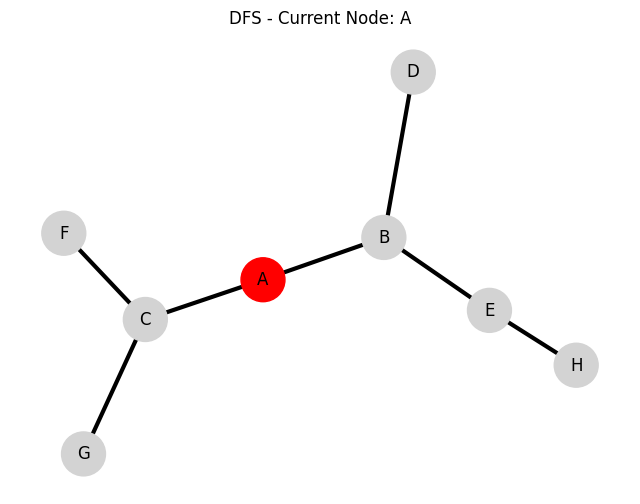

In [2]:
# Import libraries

import networkx as nx
import matplotlib.pyplot as plt

from matplotlib.animation import FuncAnimation
from IPython.display import HTML


# Create graph

G = nx.Graph()

edges = [
    ('A','B'),
    ('A','C'),
    ('B','D'),
    ('B','E'),
    ('C','F'),
    ('C','G'),
    ('E','H')
]

G.add_edges_from(edges)


# DFS Traversal

visited = []
parent = {}


def dfs(node, previous=None):

    visited.append(node)

    if previous is not None:
        parent[node] = previous

    for neighbour in sorted(G.neighbors(node)):

        if neighbour not in visited:
            dfs(neighbour, node)


# Start DFS from A

dfs('A')

print("DFS Traversal Order:")
print(visited)


# Graph Layout

pos = nx.spring_layout(G, seed=5)

fig, ax = plt.subplots(figsize=(8, 6))


# Animation

def update(frame):

    ax.clear()

    visited_now = visited[:frame + 1]

    # Visited nodes
    node_colors = [
        'red' if n in visited_now else 'lightgray'
        for n in G.nodes()
    ]

    # DFS tree edges
    edge_colors = []

    for u, v in G.edges():

        if ((v in parent and parent[v] == u and v in visited_now) or
            (u in parent and parent[u] == v and u in visited_now)):

            edge_colors.append('green')

        else:

            edge_colors.append('black')


    # Draw graph

    nx.draw(
        G,
        pos,
        ax=ax,
        with_labels=True,
        node_color=node_colors,
        edge_color=edge_colors,
        node_size=1000,
        width=3
    )

    ax.set_title(
        f"DFS - Current Node: {visited[frame]}"
    )


# Generate animation

ani = FuncAnimation(
    fig,
    update,
    frames=len(visited),
    interval=1200,
    repeat=False
)


# Display animation

HTML(ani.to_jshtml())